# Docling parse via LangChain

Trial only. This notebook is where we look at the parse. Nothing here moves into a `.py` module until you say the approach is worth keeping.

The LangChain docs MCP points at [the Docling loader page](https://docs.langchain.com/oss/python/integrations/document_loaders/docling). The reference MCP has no Docling symbols, so that page is the API we follow.

- Package: `langchain-docling`
- Import: `from langchain_docling.loader import DoclingLoader, ExportType`
- `ExportType.DOC_CHUNKS` (the default) returns one LangChain `Document` per chunk. Metadata key `dl_meta` carries headings, item labels, page numbers, and bounding boxes.
- `ExportType.MARKDOWN` returns one document for the whole file.
- `convert_kwargs` is forwarded to `DocumentConverter.convert`, which accepts `page_range`.

This run uses `DOC_CHUNKS` on the whole PDF. No `page_range` is passed, so Docling converts every page.

Picture crops are enabled on the PDF pipeline (`generate_picture_images` and `generate_page_images`). Docling's own picture-description and chart-extraction stages stay off. Text chunks come from `HierarchicalChunker`. A caption that belongs to a picture is left out of `docs`, because that figure is embedded through its picture document. Each informative picture is also appended to `docs`: `qwen/qwen3.8-27b` on Groq writes `retrieval_text` into `page_content`, and the crop is saved under `crops/` with `image_path` in metadata. The base64 form is sent only to Groq. Images the model marks as skip are not added.


In [1]:
import os
from collections import Counter
from pathlib import Path

os.environ["TOKENIZERS_PARALLELISM"] = "false"

from docling.chunking import HierarchicalChunker
from docling.datamodel.base_models import InputFormat
from docling.datamodel.pipeline_options import PdfPipelineOptions
from docling.document_converter import DocumentConverter, PdfFormatOption
from langchain_core.documents import Document
from langchain_docling.loader import ExportType

PDF_NAME = "attention-is-all-you-need.pdf"
PDF_PATH = next(
    (directory / PDF_NAME for directory in [Path.cwd(), *Path.cwd().parents] if (directory / PDF_NAME).exists()),
    Path.cwd() / PDF_NAME,
)

print(PDF_PATH.resolve(), "exists" if PDF_PATH.exists() else "MISSING")
print("export_type", ExportType.DOC_CHUNKS.value, "page_range", "all pages")


/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


/home/jovyan/multimodal-rag/attention-is-all-you-need.pdf exists
export_type doc_chunks page_range all pages


In [2]:
pipeline_options = PdfPipelineOptions(
    generate_picture_images=True,
    generate_page_images=True,
)
converter = DocumentConverter(
    format_options={
        InputFormat.PDF: PdfFormatOption(pipeline_options=pipeline_options),
    }
)
conversion = converter.convert(source=str(PDF_PATH))
dl_doc = conversion.document

chunker = HierarchicalChunker()
picture_caption_refs = {
    caption.cref
    for picture in dl_doc.pictures
    for caption in picture.captions
}

def is_picture_caption(chunk):
    refs = [item.self_ref for item in chunk.meta.doc_items]
    return bool(refs) and all(ref in picture_caption_refs for ref in refs)

text_chunks = list(chunker.chunk(dl_doc))
dropped_captions = sum(is_picture_caption(chunk) for chunk in text_chunks)
docs = [
    Document(
        page_content=chunker.contextualize(chunk=chunk),
        metadata={
            "source": str(PDF_PATH),
            "dl_meta": chunk.meta.export_json_dict(),
        },
    )
    for chunk in text_chunks
    if not is_picture_caption(chunk)
]
print("chunks", len(docs), "picture captions left out", dropped_captions)
print(
    "pictures",
    len(dl_doc.pictures),
    "tables",
    len(dl_doc.tables),
    "generate_picture_images",
    pipeline_options.generate_picture_images,
    "generate_page_images",
    pipeline_options.generate_page_images,
)


The plugin langchain_docling will not be loaded because Docling is being executed with allow_external_plugins=false.
The plugin langchain_docling will not be loaded because Docling is being executed with allow_external_plugins=false.
No OCR engine found. Please review the install details.
The plugin langchain_docling will not be loaded because Docling is being executed with allow_external_plugins=false.


Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

The plugin langchain_docling will not be loaded because Docling is being executed with allow_external_plugins=false.


chunks 84 picture captions left out 5
pictures 7 tables 4 generate_picture_images True generate_page_images True


In [3]:
def item_labels(doc):
    items = doc.metadata.get("dl_meta", {}).get("doc_items", [])
    return [item.get("label") for item in items]

label_counts = Counter(label for doc in docs for label in item_labels(doc))
print("label counts:")
for label, count in label_counts.most_common():
    print(f"  {label}: {count}")


label counts:
  text: 65
  list_item: 43
  formula: 6
  footnote: 5
  caption: 4
  table: 4


In [4]:
def page_numbers(doc):
    pages = []
    for item in doc.metadata.get("dl_meta", {}).get("doc_items", []):
        for prov in item.get("prov") or []:
            if prov.get("page_no") is not None:
                pages.append(prov["page_no"])
    return pages

all_pages = [page for doc in docs for page in page_numbers(doc)]
print("pages", min(all_pages), "to", max(all_pages), "unique", len(set(all_pages)))

shown = set()
for index, doc in enumerate(docs):
    labels = tuple(item_labels(doc))
    if labels in shown:
        continue
    shown.add(labels)
    meta = doc.metadata.get("dl_meta", {})
    print(f"\n===== first chunk with labels={list(labels)} index={index} headings={meta.get('headings')} =====")
    print(doc.page_content[:800])
    print(f"Total Words: {len(doc.page_content)}")
    pages = page_numbers(doc)
    if pages:
        print("pages", pages[:5])


pages 1 to 12 unique 12

===== first chunk with labels=['text'] index=0 headings=None =====
Provided proper attribution is provided, Google hereby grants permission to reproduce the tables and figures in this paper solely for use in journalistic or scholarly works.
Total Words: 173
pages [1]

===== first chunk with labels=['footnote'] index=4 headings=['Abstract'] =====
Abstract
∗Equal contribution. Listing order is random. Jakob proposed replacing RNNs with self-attention and started the effort to evaluate this idea. Ashish, with Illia, designed and implemented the first Transformer models and has been crucially involved in every aspect of this work. Noam proposed scaled dot-product attention, multi-head attention and the parameter-free position representation and became the other person involved in nearly every detail. Niki designed, implemented, tuned and evaluated countless model variants in our original codebase and tensor2tensor. Llion also experimented with novel model variants,


===== picture 0 label=picture page=3 bbox=[195.7201690673828, 397.9071044921875, 416.18841552734375, 719.2408905029297] image=(220, 321) =====
Figure 1: The Transformer - model architecture.


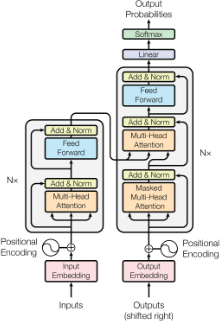

/home/jovyan/multimodal-rag/crops/attention-is-all-you-need/page-3-picture-0.png
Figure 1: The Transformer - model architecture. The diagram illustrates the encoder-decoder structure of the Transformer model. The left column represents the Encoder, which takes Inputs, passes them through an Input Embedding layer, adds Positional Encoding, and processes the result through N stacked blocks. Each encoder block consists of a Multi-Head Attention layer followed by an Add & Norm layer, and a Feed Forward layer followed by another Add & Norm layer. The right column represents the Decoder, which takes Outputs (shifted right), passes them through an Output Embedding layer, adds Positional Encoding, and processes the result through N stacked blocks. Each decoder block consists of a Masked Multi-Head Attention layer followed by an Add & Norm layer, a Multi-Head Attention layer (which also receives input from the encoder) followed by an Add & Norm layer, and a Feed Forward layer followed by an Add

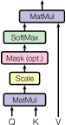

/home/jovyan/multimodal-rag/crops/attention-is-all-you-need/page-4-picture-1.png
Diagram illustrating the computational flow of a scaled dot-product attention mechanism. The process begins with inputs labeled Q, K, and V. Q and K are fed into a MatMul operation, followed by a Scale operation, an optional Mask operation, and a SoftMax operation. The output of the SoftMax operation is then passed to a second MatMul operation along with the V input. The final output is shown at the top of the diagram.

===== picture 2 label=picture page=4 bbox=[346.6099853515625, 553.8251037597656, 466.9015808105469, 720.9769287109375] image=(120, 167) =====
Figure2: (left)ScaledDot-ProductAttention. (right)Multi-HeadAttentionconsistsofseveral attention layers running in parallel.


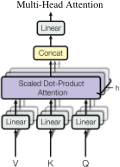

/home/jovyan/multimodal-rag/crops/attention-is-all-you-need/page-4-picture-2.png
Diagram of Multi-Head Attention architecture. The figure illustrates a neural network component where inputs V, K, and Q are processed through separate Linear layers. These inputs feed into multiple parallel Scaled Dot-Product Attention blocks, indicated by the parameter 'h' representing the number of heads. The outputs from the attention blocks are combined via a Concat operation and passed through a final Linear layer to produce the output.

===== picture 3 label=picture page=13 bbox=[106.26558685302734, 490.42547607421875, 503.7259521484375, 728.5337142944336] image=(398, 239) =====
Figure 3: An example of the attention mechanism following long-distance dependencies in the encoder self-attention in layer 5 of 6. Many of the attention heads attend to a distant dependency of the verb 'making', completing the phrase 'making...more difficult'. Attentions here shown only for the word 'making'. Different colo

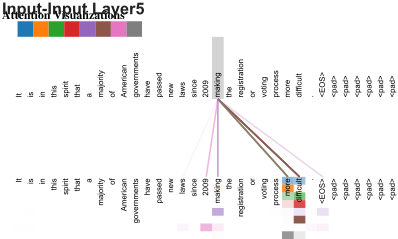

/home/jovyan/multimodal-rag/crops/attention-is-all-you-need/page-13-picture-3.png
Input-Input Layer 5 Attention Visualizations. This figure displays an attention mechanism visualization for the encoder self-attention in layer 5 of 6. The visualization focuses on the word 'making' (highlighted in grey) and shows attention lines connecting it to other words in the sequence. The text sequence includes: 'It is in this spirit that a majority of American governments have passed new laws since 2009 making the registration or voting process more difficult.' Attention lines (colored to represent different heads) extend from 'making' to 'more' and 'difficult', illustrating long-distance dependencies. A color legend at the top indicates different attention heads with colors including blue, orange, green, red, purple, brown, and pink.

===== picture 4 label=picture page=14 bbox=[107.80976104736328, 188.03570556640625, 501.40264892578125, 621.8021087646484] image=(393, 434) =====
Figure 4: Two atte

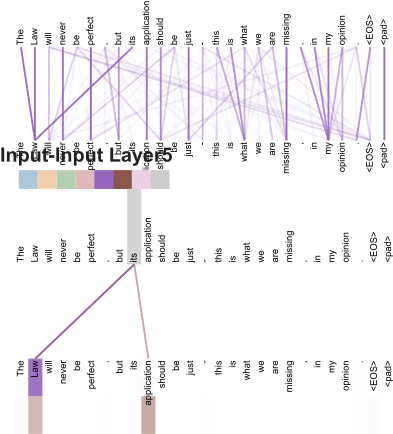

/home/jovyan/multimodal-rag/crops/attention-is-all-you-need/page-14-picture-4.png
Figure 4: Attention visualization for two attention heads in layer 5 of 6, involved in anaphora resolution. The figure displays attention maps for the input sequence 'The Law will never be perfect . but its application should be just . this is what we are missing . in my opinion . <EOS> <pad>'. The top panel shows full attentions for head 5, with connections between various tokens. The bottom panel isolates attentions originating from the word 'its' for attention heads 5 and 6. The visualization highlights sharp attention patterns, specifically showing strong attention from 'its' to 'Law' and 'application', indicating the resolution of the pronoun to its antecedent.

===== picture 5 label=picture page=15 bbox=[124.5443115234375, 634.5773010253906, 276.11993408203125, 654.8307647705078] image=(151, 20) =====
skip: smaller than 32 pixels

===== picture 6 label=picture page=15 bbox=[106.20919799804688, 201.9

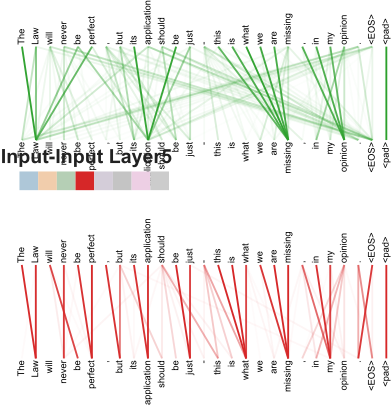

/home/jovyan/multimodal-rag/crops/attention-is-all-you-need/page-15-picture-6.png
Figure 5: Visualization of attention heads from the encoder self-attention at layer 5 of 6. The figure displays two examples of attention patterns, illustrating that different heads have learned to perform different tasks related to sentence structure. The visualizations show connections (lines) between input tokens, with line thickness and color (green and red) indicating the strength and type of attention. The input sentence tokens include: 'The', 'Law', 'will', 'never', 'be', 'perfect', ',', 'but', 'its', 'application', 'should', 'be', 'just', '-', 'this', 'is', 'what', 'we', 'are', 'missing', '.', 'in', 'my', 'opinion', '.', '<EOS>', '<pad>'. The top panels show green attention lines, while the bottom panels show red attention lines, highlighting distinct focus areas for each head.

picture docs kept 6 skipped 1 docs 90


In [5]:
import base64
import json
from io import BytesIO

from dotenv import load_dotenv
from IPython.display import display
from langchain_core.messages import HumanMessage
from langchain_groq import ChatGroq

env_path = next(
    (directory / ".env" for directory in [Path.cwd(), *Path.cwd().parents] if (directory / ".env").exists()),
    None,
)
if env_path is not None:
    load_dotenv(env_path)

PICTURE_PROMPT = """You describe a figure so it can be retrieved by search.

Return JSON only, with no markdown fence:
{"skip": false, "retrieval_text": "..."}

Set skip to true for a header, footer, page number, logo, icon, or any other image that is not informative. When skip is true, retrieval_text must be an empty string.

When skip is false, retrieval_text is a search document. Include the metric, period, comparison basis, units, and series, and only values that are readable in the image. Do not invent values that are not visible. If the figure is informative but has no numeric series, describe only what is readable.

A native caption is context. It does not add values that are not in the image. If a Docling chart table is included, use it only where it matches the image, and still describe the figure from the crop.
"""

picture_model = ChatGroq(
    model="qwen/qwen3.8-27b",
    temperature=0,
    reasoning_format="parsed",
)


def parse_picture_response(raw):
    text = raw.strip()
    if text.startswith("```"):
        lines = text.splitlines()[1:]
        if lines and lines[-1].strip().startswith("```"):
            lines = lines[:-1]
        text = "\n".join(lines).strip()
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        start = text.find("{")
        end = text.rfind("}")
        if start == -1 or end <= start:
            raise
        return json.loads(text[start : end + 1])


def chart_table_text(picture):
    meta = picture.meta
    tabular = meta.tabular_chart if meta is not None else None
    if tabular is None or tabular.chart_data is None:
        return ""
    return f"\nDocling chart table:\n{tabular.chart_data}"


docs = [doc for doc in docs if doc.metadata.get("element_type") != "picture"]
kept = 0
skipped = 0

for index, picture in enumerate(dl_doc.pictures):
    image = picture.get_image(dl_doc)
    prov = picture.prov[0] if picture.prov else None
    page = prov.page_no if prov is not None else None
    bbox = list(prov.bbox.as_tuple()) if prov is not None else None
    caption = picture.caption_text(dl_doc)
    print(
        f"\n===== picture {index} label={picture.label} page={page} bbox={bbox} image={None if image is None else image.size} ====="
    )
    if caption:
        print(caption)
    if image is None:
        print("skip: no crop")
        skipped += 1
        continue

    if image.width < 32 or image.height < 32:
        print("skip: smaller than 32 pixels")
        skipped += 1
        continue

    display(image)
    buffer = BytesIO()
    image.save(buffer, format="PNG")
    image_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

    context = PICTURE_PROMPT
    if caption:
        context += f"\nNative caption: {caption}"
    context += chart_table_text(picture)
    response = picture_model.invoke(
        [
            HumanMessage(
                content=[
                    {"type": "text", "text": context},
                    {"type": "image", "base64": image_b64, "mime_type": "image/png"},
                ]
            )
        ]
    )
    parsed = parse_picture_response(response.content)
    if parsed.get("skip"):
        print("skip: model")
        skipped += 1
        continue

    retrieval_text = (parsed.get("retrieval_text") or "").strip()
    if not retrieval_text:
        print("skip: empty retrieval_text")
        skipped += 1
        continue

    crop_dir = PDF_PATH.parent / "crops" / PDF_PATH.stem
    crop_dir.mkdir(parents=True, exist_ok=True)
    image_path = crop_dir / f"page-{page}-picture-{index}.png"
    image_path.write_bytes(buffer.getvalue())

    docs.append(
        Document(
            page_content=retrieval_text,
            metadata={
                "source": str(PDF_PATH),
                "element_type": "picture",
                "page": page,
                "bbox": bbox,
                "caption": caption,
                "image_path": str(image_path),
            },
        )
    )
    kept += 1
    print(image_path)
    print(retrieval_text)

print("\npicture docs kept", kept, "skipped", skipped, "docs", len(docs))


In [6]:
from pprint import pprint
pprint(docs[1])

Document(metadata={'source': '/home/jovyan/multimodal-rag/attention-is-all-you-need.pdf', 'dl_meta': {'schema_name': 'docling_core.transforms.chunker.DocMeta', 'version': '1.0.0', 'doc_items': [{'self_ref': '#/texts/3', 'parent': {'$ref': '#/body'}, 'children': [], 'content_layer': 'body', 'label': 'text', 'prov': [{'page_no': 1, 'bbox': {'l': 116.68099999999998, 't': 557.6831053999999, 'r': 216.0390060600002, 'b': 525.2753028, 'coord_origin': 'BOTTOMLEFT'}, 'charspan': [0, 48]}, {'page_no': 1, 'bbox': {'l': 230.69199999999998, 't': 557.6831053999999, 'r': 309.1325310999999, 'b': 525.2753028, 'coord_origin': 'BOTTOMLEFT'}, 'charspan': [49, 91]}, {'page_no': 1, 'bbox': {'l': 323.787, 't': 557.6831053999999, 'r': 407.4568998399997, 'b': 525.2753028, 'coord_origin': 'BOTTOMLEFT'}, 'charspan': [92, 137]}, {'page_no': 1, 'bbox': {'l': 422.11199999999997, 't': 557.6831053999999, 'r': 497.21276514, 'b': 525.2753028, 'coord_origin': 'BOTTOMLEFT'}, 'charspan': [138, 185]}]}], 'headings': ['Atte

## Embed and store

Nemotron on OpenRouter is text-only and 2048-dimensional. Passages are embedded with `input_type=passage` and the test query with `input_type=query`. The index is `multimodal-rag` (cosine). The existing `rag` index is 384-dimensional, so it cannot hold these vectors. Metadata stored on each vector is flat: `element_type`, `page`, `bbox`, `headings` for text, and `image_path` for pictures.

In [7]:
import json
import time

from langchain_openai import OpenAIEmbeddings
from langchain_pinecone import PineconeVectorStore
from pinecone import Pinecone, ServerlessSpec

load_dotenv(env_path)

INDEX_NAME = "multimodal-rag"
EMBED_MODEL = "nvidia/nemotron-3-embed-1b:free"


def make_embeddings(input_type):
    return OpenAIEmbeddings(
        model=EMBED_MODEL,
        api_key=os.environ["OPENROUTER_API_KEY"],
        base_url="https://openrouter.ai/api/v1",
        check_embedding_ctx_length=False,
        model_kwargs={"extra_body": {"input_type": input_type}},
    )


def cosine(left, right):
    dot = sum(a * b for a, b in zip(left, right))
    left_norm = sum(a * a for a in left) ** 0.5
    right_norm = sum(b * b for b in right) ** 0.5
    return dot / (left_norm * right_norm)


def pinecone_metadata(doc):
    meta = {"source": str(doc.metadata.get("source", ""))}
    if doc.metadata.get("element_type") == "picture":
        meta["element_type"] = "picture"
        if doc.metadata.get("page") is not None:
            meta["page"] = int(doc.metadata["page"])
        if doc.metadata.get("bbox") is not None:
            meta["bbox"] = json.dumps(doc.metadata["bbox"])
        if doc.metadata.get("image_path"):
            meta["image_path"] = doc.metadata["image_path"]
        if doc.metadata.get("caption"):
            meta["caption"] = doc.metadata["caption"]
        return meta

    dl_meta = doc.metadata.get("dl_meta") or {}
    items = dl_meta.get("doc_items") or []
    labels = [item.get("label") for item in items if item.get("label")]
    meta["element_type"] = labels[0] if labels else "text"
    page = None
    bbox = None
    for item in items:
        for prov in item.get("prov") or []:
            if page is None and prov.get("page_no") is not None:
                page = int(prov["page_no"])
            if bbox is None and prov.get("bbox"):
                box = prov["bbox"]
                bbox = [box.get("l"), box.get("t"), box.get("r"), box.get("b")]
    if page is not None:
        meta["page"] = page
    if bbox is not None:
        meta["bbox"] = json.dumps(bbox)
    headings = dl_meta.get("headings") or []
    if headings:
        meta["headings"] = " > ".join(headings)
    return meta


passage_embeddings = make_embeddings("passage")
query_embeddings = make_embeddings("query")

probe = "scaled dot-product attention"
passage_vector = passage_embeddings.embed_documents([probe])[0]
query_vector = query_embeddings.embed_query(probe)
print(
    "dimensions",
    len(passage_vector),
    len(query_vector),
    "passage vs query cosine",
    round(cosine(passage_vector, query_vector), 4),
)

pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])
existing = [index_info["name"] for index_info in pc.list_indexes()]
if INDEX_NAME not in existing:
    pc.create_index(
        name=INDEX_NAME,
        dimension=2048,
        metric="cosine",
        spec=ServerlessSpec(cloud="aws", region="us-east-1"),
    )
    while not pc.describe_index(INDEX_NAME).status["ready"]:
        time.sleep(1)

index = pc.Index(INDEX_NAME)
described = pc.describe_index(INDEX_NAME)
print("index", INDEX_NAME, "dimension", described.dimension, "metric", described.metric)

store_docs = [
    Document(page_content=doc.page_content, metadata=pinecone_metadata(doc))
    for doc in docs
    if doc.page_content.strip()
]
ids = [f"chunk-{i}" for i in range(len(store_docs))]
vector_store = PineconeVectorStore(index=index, embedding=passage_embeddings)
vector_store.add_documents(store_docs, ids=ids)
print("upserted", len(store_docs))

query_store = PineconeVectorStore(index=index, embedding=query_embeddings)
question = "How does multi-head attention work?"
hits = query_store.similarity_search_with_score(question, k=3)
print("\nquestion:", question)
for rank, (hit, score) in enumerate(hits, start=1):
    print(
        f"\n#{rank} score={score:.4f} type={hit.metadata.get('element_type')} page={hit.metadata.get('page')} headings={hit.metadata.get('headings')}"
    )
    if hit.metadata.get("image_path"):
        print("image_path", hit.metadata["image_path"])
    print(hit.page_content[:400])


dimensions 2048 2048 passage vs query cosine 0.8581
index multimodal-rag dimension 2048 metric cosine
upserted 90

question: How does multi-head attention work?

#1 score=0.6204 type=text page=5.0 headings=3.2.2 Multi-HeadAttention
3.2.2 Multi-HeadAttention
Multi-head attention allows the model to jointly attend to information from different representation subspaces at different positions. With a single attention head, averaging inhibits this.

#2 score=0.5597 type=text page=5.0 headings=3.2.2 Multi-HeadAttention
3.2.2 Multi-HeadAttention
In this work we employ h = 8 parallel attention layers, or heads. For each of these we use dk = dv = dmodel/h = 64. Due to the reduced dimension of each head, the total computational cost is similar to that of single-head attention with full dimensionality.

#3 score=0.5439 type=text page=4.0 headings=3.2.2 Multi-HeadAttention
3.2.2 Multi-HeadAttention
Instead of performing a single attention function with dmodel-dimensional keys, values and queries, 